# Eigenfunctions of the Koopman operator

**Adapted from**: Example 2.6 of [MAI20]

[MAI20] Mauroy, Alexandre, Aivar Sootla, and Igor Mezić.
*Koopman framework for global stability analysis.*
The Koopman Operator in Systems and Control: Concepts, Methodologies,
and Applications (2020): 35-58.

In [1]:
using DynamicPolynomials
using LinearAlgebra
@polyvar x[1:2]

a = 1
I = 0.05
ε = 0.08
γ = 1
F0 = [-x[2] - x[1] * (x[1] - 1) * (x[1] - a) + I, ε * (x[1] - γ * x[2])]

2-element Vector{DynamicPolynomials.Polynomial{Float64}}:
 0.05 - x₂ - x₁ + 2.0x₁² - x₁³
 -0.08x₂ + 0.08x₁

We move the equilibrium, approximately `(0.0256, 0.0256)`, to the origin.
Since `γ = 1`, both coordinates are equal. Newton's method refines the
rounded value so that the translated vector field vanishes at the origin.

In [2]:
x_eq = let z = 0.0256
    for _ in 1:5
        z -= (-z - z * (z - 1)^2 + I) / (-2 + 4z - 3z^2)
    end
    z
end
F = [f(x => x .+ x_eq) for f in F0]

2-element Vector{DynamicPolynomials.Polynomial{Float64}}:
 -3.7100043089738355e-18 - x₂ - 0.8993758546202244x₁ + 1.9230516279758776x₁² - x₁³
 -0.08x₂ + 0.08x₁

We compute the Jacobian at the equilibrium.

In [3]:
J = [j(x => zeros(2)) for j in differentiate(F, x)]

2×2 Matrix{Float64}:
 -0.899376  -1.0
  0.08      -0.08

Its eigenvalues have negative real part. The linear term `w ⋅ x` of a
Koopman eigenfunction must satisfy `J' * w = λ * w`, so we need a **left**
eigenvector of `J`. A right eigenvector leaves a nonzero linear residual
which the higher-degree terms cannot cancel. We therefore use a left
eigenvector instead of the right eigenvector stated in Example 2.6,
consistently with Eq. (2.7) on p. 42 of the book.

In [4]:
E = eigen(J')
λ = E.values[end]
w = E.vectors[:, end]

2-element Vector{Float64}:
 -0.11258237486231153
 -0.9936423948636461

Eigenfunctions are defined up to a scalar factor. We choose a unit gradient
with positive second component to fix the sign of the contour labels.
Figure 2.3 appears to use the original coordinates, with the equilibrium
at `(x_eq, x_eq)`, and a different normalization. Our axes are shifted to
the equilibrium and our gradient has unit norm, so the contour labels
need not coincide with those in the book.

In [5]:
if w[2] < 0
    w = -w
end

2-element Vector{Float64}:
 0.11258237486231153
 0.9936423948636461

We approximate the eigenfunction on the disk of radius `r`. Working in
coordinates `y = x / r` avoids the very small high-degree monomials on
this disk. The scaled vector field is `G(y) = F(r * y) / r`.

In [6]:
using SumOfSquares
r = 0.3
@polyvar y[1:2]
G = [f(x => r .* y) / r for f in F]
X = @set y[1]^2 + y[2]^2 ≤ 1

Basic semialgebraic Set defined by no equality
1 inequality
 1 - y[2]^2 - y[1]^2 ≥ 0


We define the program for the FitzHugh-Nagumo problem below:
`N` is the degree of `ϕN` as defined in [MAI20, p. 50] and `M` is the
degree of the multipliers for the constraints of `X`.
As `maxdegree` corresponds to the degree of the multiplier multiplied
by `1 - y[1]^2 - y[2]^2`, we set it to `M + 2`.

In [7]:
function fitzhugh_nagumo(solver, N, M)
    model = SOSModel(solver)
    @variable(model, η)
    @objective(model, Min, η)
    @variable(model, ϕN, Poly(monomials(y, 2:N)))
    ϕ = r * (w ⋅ y) + ϕN
    residual = G ⋅ differentiate(ϕ, y) - λ * ϕ
    @constraint(model, -η ≤ residual, domain = X, maxdegree = M + 2)
    @constraint(model, residual ≤ η, domain = X, maxdegree = M + 2)
    optimize!(model)
    return ϕ(y => x ./ r), model
end

fitzhugh_nagumo (generic function with 1 method)

In [MAI20, p. 50], the result is obtained with `N = 10` and `M = 20`.

In [8]:
import CSDP
solver = optimizer_with_attributes(CSDP.Optimizer, MOI.Silent() => true)
ϕ, model = fitzhugh_nagumo(solver, 10, 20)
solution_summary(model)

solution_summary(; result = 1, verbose = false)
├ solver_name          : CSDP
├ Termination
│ ├ termination_status : OPTIMAL
│ ├ result_count       : 1
│ └ raw_status         : Problem solved to optimality.
├ Solution (result = 1)
│ ├ primal_status        : FEASIBLE_POINT
│ ├ dual_status          : FEASIBLE_POINT
│ ├ objective_value      : 7.98206e-06
│ └ dual_objective_value : 7.98004e-06
└ Work counters
  └ solve_time (sec)   : 6.73111e-01

The optimal polynomial is obtained as follows:

In [9]:
ϕ_opt = value(ϕ)
residual_opt = F ⋅ differentiate(ϕ_opt, x) - λ * ϕ_opt

-4.176810958536834e-19 - 2.7755575615628914e-17x₂ - 3.122502256758253e-17x₁ + 0.001589117951892538x₂² - 0.0017526156606608185x₁x₂ - 0.0005623871357281554x₁² - 0.0041009891176863045x₂³ - 0.008867718701428414x₁x₂² + 0.031128772738132367x₁²x₂ - 0.004558255532275658x₁³ - 0.13813749046498236x₂⁴ + 0.23999434702416225x₁x₂³ - 0.19839166220131488x₁²x₂² + 0.16011222666642305x₁³x₂ + 0.05182033487882621x₁⁴ + 0.2100627555294753x₂⁵ + 0.23463440977428335x₁x₂⁴ - 1.7688819897590162x₁²x₂³ + 2.321051440816212x₁³x₂² - 2.1517780831582964x₁⁴x₂ + 0.12894001390622736x₁⁵ + 3.713559679457825x₂⁶ - 9.018163471224351x₁x₂⁵ + 12.537736733958404x₁²x₂⁴ - 13.278552560239277x₁³x₂³ + 6.302892741839159x₁⁴x₂² - 4.758976851131787x₁⁵x₂ - 1.5456943303916357x₁⁶ - 3.1399698923511323x₂⁷ - 0.7973811338395951x₁x₂⁶ + 28.21768417298625x₁²x₂⁵ - 77.54216887725512x₁³x₂⁴ + 116.61669697139598x₁⁴x₂³ - 79.88698746778421x₁⁵x₂² + 44.76755368463776x₁⁶x₂ + 0.12308496242172713x₁⁷ - 39.51048804914126x₂⁸ + 125.9779059787154x₁x₂⁷ - 218.95742326185

We plot its level sets inside the disk where the residual is constrained.
Values outside this disk are extrapolations and are excluded from both
the plot and the error calculation below.

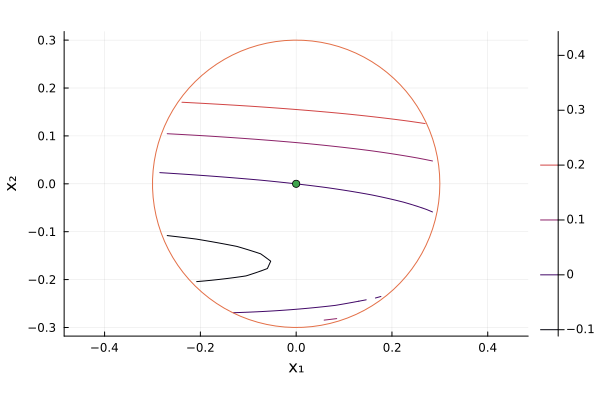

In [10]:
using Plots
x1s = x2s = range(-r, r, length = 40)
inside = [u^2 + v^2 ≤ r^2 for v in x2s, u in x1s]
ϕs = [
    inside[i, j] ? ϕ_opt(x => [u, v]) : NaN for
    (i, v) in enumerate(x2s), (j, u) in enumerate(x1s)
]
contour(
    x1s,
    x2s,
    ϕs;
    levels = [-0.2, -0.1, 0, 0.1, 0.2, 0.5, 0.7],
    aspect_ratio = :equal,
    xlabel = "x₁",
    ylabel = "x₂",
)
θ = range(0, 2π, length = 100)
plot!(r * cos.(θ), r * sin.(θ), label = "")
scatter!([0], [0], label = "")

We can check the Koopman identity using the finite-time Laplace average
of `ϕ_opt`. An exact eigenfunction satisfies
`exp(-λ * t) * ϕ(S(t, x)) = ϕ(x)` along a trajectory.
Solve each trajectory once, then integrate using its dense interpolant.
Tight tolerances matter because `exp(-λ * t)` amplifies integration errors.

In [11]:
import OrdinaryDiffEqTsit5
using QuadGK
function laplace_average(f, λ, x1, x2, T = 10.0)
    prob = OrdinaryDiffEqTsit5.ODEProblem(
        (v, p, t) -> [g(x => v) for g in F],
        [x1, x2],
        (0.0, T),
    )
    traj = OrdinaryDiffEqTsit5.solve(
        prob,
        OrdinaryDiffEqTsit5.Tsit5();
        reltol = 1e-11,
        abstol = 1e-13,
    )
    v, _ = quadgk(t -> f(traj(t)) * exp(-λ * t), 0.0, T; rtol = 1e-7)
    return v / T
end

lap(x1, x2) = laplace_average(v -> ϕ_opt(x => v), λ, x1, x2)
laplace = [
    inside[i, j] ? lap(u, v) : NaN for
    (i, v) in enumerate(x2s), (j, u) in enumerate(x1s)
]

40×40 Matrix{Float64}:
 NaN  NaN  NaN  NaN  NaN         …  NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN         …  NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN   -0.110708      -0.0401727  NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN   -0.111655      -0.0455329  NaN  NaN  NaN  NaN
   ⋮                             ⋱    ⋮                         
 NaN  NaN  NaN  NaN    0.210627       0.273319   NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN            NaN          NaN  NaN  NaN  NaN
 NaN  NaN  NaN  NaN  NaN    

We report the maximum absolute discrepancy on the disk. Unlike a matrix
norm over the enclosing square, this error excludes unconstrained points
and does not grow merely because the grid is refined. It checks the
eigenfunction identity over a finite time, rather than providing a bound
on the error with respect to the exact eigenfunction.

In [12]:
maximum(abs, laplace[inside] - ϕs[inside])

0.02288408073433648

The disk is not forward invariant: some trajectories starting inside it
leave it, so a small residual on the disk does not guarantee a small
Laplace-average discrepancy for all those initial states. Increasing `T`
does not fix extrapolation outside the approximation domain. For initial
states in the smaller disk of radius `r / 2`, the discrepancy is much
smaller:

In [13]:
inner = [u^2 + v^2 ≤ (r / 2)^2 for v in x2s, u in x1s]
maximum(abs, laplace[inner] - ϕs[inner])

6.18791052426626e-5

The finite-time identity discrepancies above need not match the error
reported in the book, especially when eigenfunctions have different
scalar normalizations.

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*